# Student Grade Predictor

**Goal:** predict a student's final grade `G3` (0-20) from academic and student-related features using supervised **regression** in scikit-learn.

**Pipeline:** load data -> EDA -> missing values -> feature engineering -> train/test split -> preprocessing (`ColumnTransformer`) -> models -> evaluation (R², RMSE) -> residual analysis.

> Data note: `data/student-mat.csv` has the same columns as the public UCI *Student Performance* dataset. The file shipped here is synthetic; drop in the real `student-mat.csv` and re-run everything unchanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (6, 4)

## 1. Load the data

In [2]:
df = pd.read_csv("data/student-mat.csv")
if df.shape[1] == 1:                      # the real UCI file is semicolon separated
    df = pd.read_csv("data/student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,MS,F,18,U,LE3,T,0.0,4.0,services,at_home,...,5,5,5,2,4,1,2.0,11,11,11
1,GP,F,20,U,GT3,T,0.0,1.0,teacher,at_home,...,2,4,1,1,1,2,10.0,8,6,5
2,GP,M,15,U,GT3,T,1.0,0.0,services,at_home,...,3,5,4,1,5,5,0.0,14,15,14
3,GP,F,18,R,GT3,T,3.0,3.0,teacher,health,...,3,2,2,1,4,3,9.0,13,13,14
4,MS,M,16,U,LE3,T,0.0,0.0,at_home,at_home,...,2,4,1,1,2,5,9.0,4,4,4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      395 non-null    str    
 1   sex         395 non-null    str    
 2   age         395 non-null    int64  
 3   address     395 non-null    str    
 4   famsize     395 non-null    str    
 5   Pstatus     395 non-null    str    
 6   Medu        384 non-null    float64
 7   Fedu        384 non-null    float64
 8   Mjob        384 non-null    str    
 9   Fjob        395 non-null    str    
 10  reason      395 non-null    str    
 11  guardian    395 non-null    str    
 12  traveltime  395 non-null    int64  
 13  studytime   388 non-null    float64
 14  failures    395 non-null    int64  
 15  schoolsup   395 non-null    str    
 16  famsup      395 non-null    str    
 17  paid        395 non-null    str    
 18  activities  395 non-null    str    
 19  nursery     395 non-null    str    
 20 

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,395.0,18.04,1.96,15.0,16.0,18.0,20.0,21.0
Medu,384.0,2.03,1.45,0.0,1.0,2.0,3.0,4.0
Fedu,384.0,2.02,1.39,0.0,1.0,2.0,3.0,4.0
traveltime,395.0,2.44,1.09,1.0,1.0,2.0,3.0,4.0
studytime,388.0,2.03,0.84,1.0,1.0,2.0,3.0,4.0
failures,395.0,0.70,0.74,0.0,0.0,1.0,1.0,3.0
famrel,395.0,3.02,1.39,1.0,2.0,3.0,4.0,5.0
freetime,395.0,3.03,1.42,1.0,2.0,3.0,4.0,5.0
goout,395.0,3.07,1.43,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.59,0.75,1.0,1.0,1.0,2.0,4.0


## 2. Missing values

In [5]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False).to_frame("missing count")

,missing count
internet,15
absences,15
Fedu,11
Medu,11
Mjob,11
studytime,7


Missing values exist in a few columns. We will **not** drop rows (we only have ~400). Instead we impute inside the modelling pipeline: **median** for numeric, **most frequent** for categorical. Doing it inside the pipeline means statistics are learned from the training set only, which avoids data leakage.

## 3. Exploratory data analysis

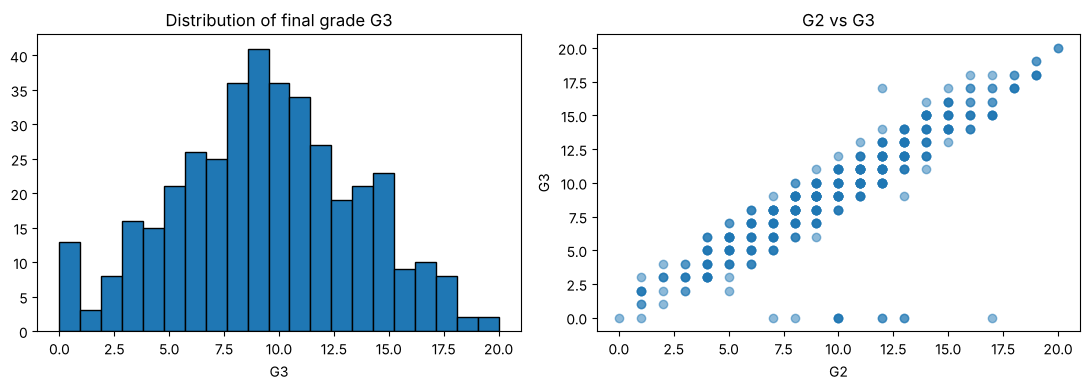

Students with G3 == 0 (dropouts): 13


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["G3"], bins=21, edgecolor="black")
ax[0].set_title("Distribution of final grade G3"); ax[0].set_xlabel("G3")
ax[1].scatter(df["G2"], df["G3"], alpha=0.5)
ax[1].set_title("G2 vs G3"); ax[1].set_xlabel("G2"); ax[1].set_ylabel("G3")
plt.tight_layout(); plt.show()
print("Students with G3 == 0 (dropouts):", (df["G3"] == 0).sum())

The histogram shows a spike at 0: students who dropped out. Those are hard for any model to predict from features alone, and they will show up later as large residuals.

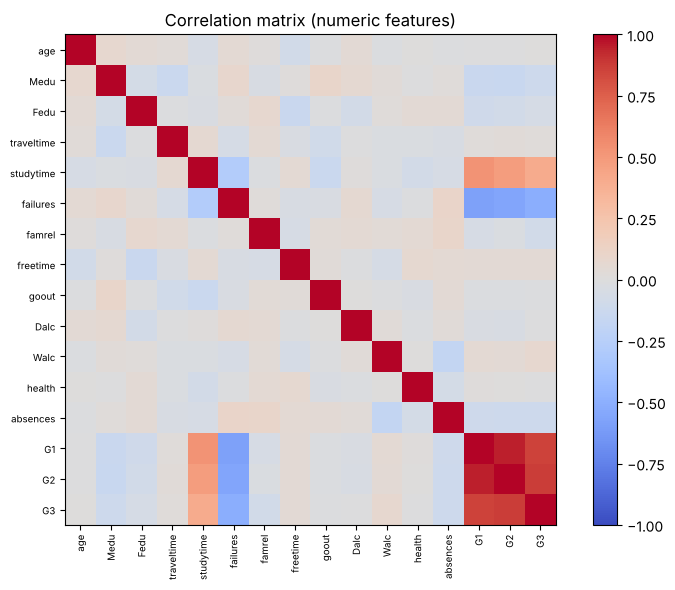

,corr with G3
G2,0.87
G1,0.86
failures,-0.50
studytime,0.41
absences,-0.12
Medu,-0.11
famrel,-0.08
Walc,0.08


In [7]:
num_cols_all = df.select_dtypes("number").columns
corr = df[num_cols_all].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
plt.colorbar(im); ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.show()
corr["G3"].drop("G3").sort_values(key=abs, ascending=False).head(8).round(2).to_frame("corr with G3")

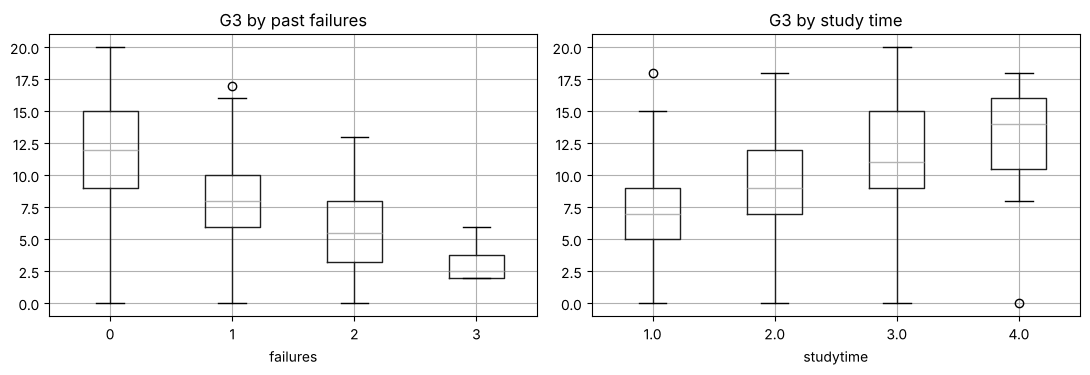

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="G3", by="failures", ax=ax[0]); ax[0].set_title("G3 by past failures"); ax[0].set_xlabel("failures")
df.boxplot(column="G3", by="studytime", ax=ax[1]); ax[1].set_title("G3 by study time"); ax[1].set_xlabel("studytime")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Findings:** G1 and G2 (earlier grades) are by far the strongest predictors of G3. More past failures lowers grades; more study time raises them a little.

## 4. Feature engineering
New features built from existing ones:
- `parent_edu` = mean of mother's and father's education
- `alcohol` = weekday + weekend alcohol consumption
- `log_absences` = `log1p(absences)`, since absences are right-skewed
- `has_failed` = 1 if the student has any past failure

In [9]:
def add_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["parent_edu"] = d[["Medu", "Fedu"]].mean(axis=1)      # NaN only if both missing
    d["alcohol"] = d["Dalc"] + d["Walc"]
    d["log_absences"] = np.log1p(d["absences"])
    d["has_failed"] = (d["failures"] > 0).astype(int)
    return d

df_fe = add_features(df)
df_fe[["Medu", "Fedu", "parent_edu", "Dalc", "Walc", "alcohol", "absences", "log_absences", "failures", "has_failed"]].head()

,Medu,Fedu,parent_edu,Dalc,Walc,alcohol,absences,log_absences,failures,has_failed
0,0.0,4.0,2.0,2,4,6,2.0,1.098612,1,1
1,0.0,1.0,0.5,1,1,2,10.0,2.397895,1,1
2,1.0,0.0,0.5,1,5,6,0.0,0.000000,0,0
3,3.0,3.0,3.0,1,4,5,9.0,2.302585,0,0
4,0.0,0.0,0.0,1,2,3,9.0,2.302585,2,1


## 5. Train / test split
80% train, 20% test. The test set is touched **once**, at the end, for the final numbers.

We build two feature sets:
- **A: with G1 and G2**: very accurate, but only usable once earlier grades exist.
- **B: without G1 and G2**: a harder, more realistic "early warning" setting using only background and behaviour features.

In [10]:
y = df_fe["G3"]
X_all = df_fe.drop(columns=["G3"])
X_noprev = X_all.drop(columns=["G1", "G2"])

def split(X):
    return train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

Xa_tr, Xa_te, y_tr, y_te = split(X_all)
Xb_tr, Xb_te, _, _ = split(X_noprev)
print("train:", Xa_tr.shape, "test:", Xa_te.shape)

train: (316, 36) test: (79, 36)


## 6. Preprocessing pipeline
- Numeric columns: impute with **median**, then **standardize** (matters for linear/Ridge models; harmless for trees)
- Categorical columns: impute with **most frequent**, then **one-hot encode** (`handle_unknown="ignore"` so unseen categories at test time do not crash)

In [11]:
def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    num = X.select_dtypes("number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

def make_models(X):
    pre = lambda: make_preprocessor(X)
    return {
        "Baseline (predict mean)": Pipeline([("pre", pre()), ("m", DummyRegressor(strategy="mean"))]),
        "Linear Regression": Pipeline([("pre", pre()), ("m", LinearRegression())]),
        "Ridge (alpha=10)": Pipeline([("pre", pre()), ("m", Ridge(alpha=10))]),
        "Random Forest": Pipeline([("pre", pre()), ("m", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
    }

## 7. Train and evaluate
**RMSE** is in grade points (same units as G3, penalises big errors). **R²** is the fraction of variance explained (1 = perfect, 0 = no better than predicting the mean). Cross-validation on the training set shows how stable each model is.

In [12]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def evaluate(X_tr, X_te, label):
    rows, fitted = [], {}
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for name, model in make_models(X_tr).items():
        cv_rmse = -cross_val_score(model, X_tr, y_tr, cv=cv, scoring="neg_root_mean_squared_error")
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)
        rows.append({"model": name, "CV RMSE (train)": cv_rmse.mean().round(2),
                     "Test RMSE": round(rmse(y_te, pred), 2), "Test R2": round(r2_score(y_te, pred), 3)})
        fitted[name] = model
    print(label)
    return pd.DataFrame(rows).set_index("model"), fitted

res_a, models_a = evaluate(Xa_tr, Xa_te, "A) WITH G1 and G2")
res_a

A) WITH G1 and G2


,CV RMSE (train),Test RMSE,Test R2
model,,,
Baseline (predict mean),4.37,4.37,-0.014
Linear Regression,2.17,2.52,0.662
Ridge (alpha=10),2.11,2.49,0.671
Random Forest,2.09,2.47,0.677


In [13]:
res_b, models_b = evaluate(Xb_tr, Xb_te, "B) WITHOUT G1 and G2 (early-warning setting)")
res_b

B) WITHOUT G1 and G2 (early-warning setting)


,CV RMSE (train),Test RMSE,Test R2
model,,,
Baseline (predict mean),4.37,4.37,-0.014
Linear Regression,4.08,3.62,0.305
Ridge (alpha=10),3.97,3.59,0.318
Random Forest,3.93,3.53,0.338


**Reading the tables**
- Every real model beats the mean baseline (R² of 0).
- Setting A (with G1/G2) is roughly twice as good as setting B in R² (about 0.67 vs 0.33), because G2 is nearly a copy of G3 plus noise. The honest message: background features alone only partly explain performance.
- Even in A, R² is capped around 0.67 because the dropouts (G3 = 0) cannot be predicted and contribute very large squared errors to RMSE.
- Linear, Ridge and Random Forest are close in A, so a simple, interpretable model is enough there.
- These numbers come from the shipped synthetic data. Re-run on the real UCI file and quote *those* numbers, never these.

## 8. Residual analysis (best model in setting A)

Best model: Random Forest


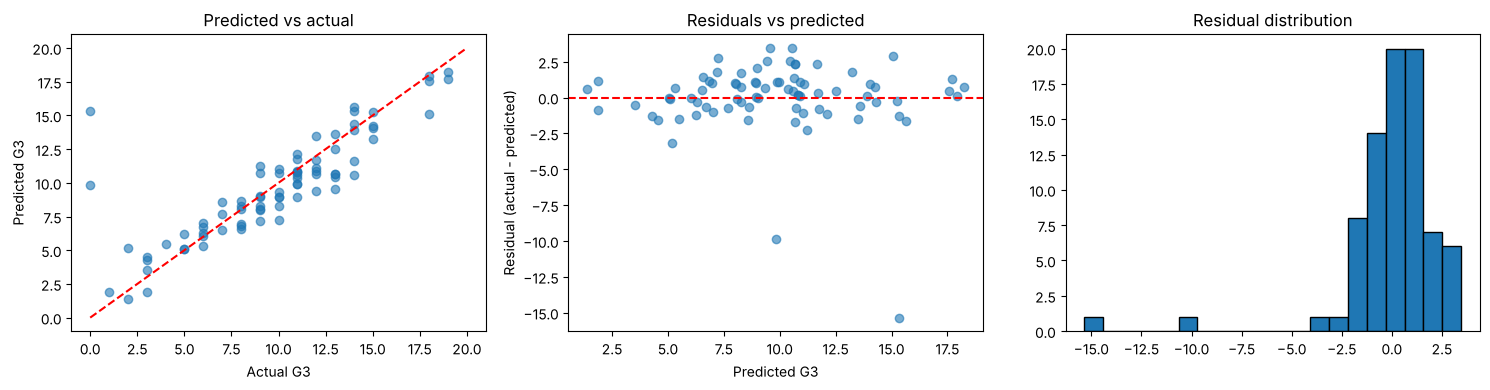

Mean residual: 0.03 | Std: 2.48
Largest errors:


,actual,predicted,residual
371,0,15.3,-15.3
285,0,9.8,-9.8
209,13,9.5,3.5
323,14,10.6,3.4
55,2,5.2,-3.2


In [14]:
best_name = res_a["Test RMSE"].idxmin()
best = models_a[best_name]
pred = best.predict(Xa_te)
resid = y_te - pred
print("Best model:", best_name)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_te, pred, alpha=0.6); ax[0].plot([0, 20], [0, 20], "r--")
ax[0].set_xlabel("Actual G3"); ax[0].set_ylabel("Predicted G3"); ax[0].set_title("Predicted vs actual")
ax[1].scatter(pred, resid, alpha=0.6); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted G3"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residuals vs predicted")
ax[2].hist(resid, bins=20, edgecolor="black"); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

print("Mean residual: %.2f | Std: %.2f" % (resid.mean(), resid.std()))
print("Largest errors:")
(pd.DataFrame({"actual": y_te, "predicted": pred.round(1), "residual": resid.round(1)})
   .reindex(resid.abs().sort_values(ascending=False).index).head(5))

**What a healthy residual plot looks like:** points scattered randomly around 0 with no curve or funnel. Here the residuals are roughly centred on 0, but the two largest errors are students whose true G3 is 0 (dropouts) while the model predicts a normal grade. The model cannot know a student will drop out, which is a real limitation, not a bug. A funnel shape (errors growing with predicted value) would indicate heteroscedasticity, and a curve would indicate a missed non-linear relationship.

## 9. Which features matter?

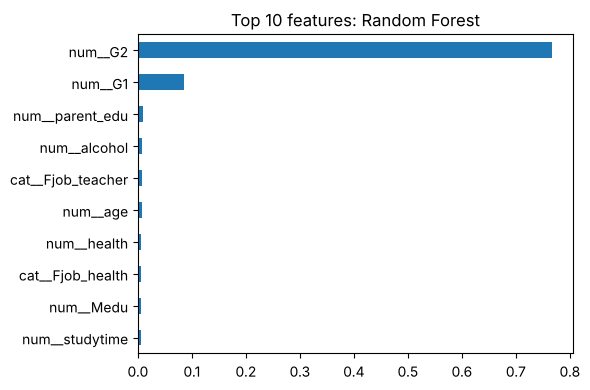

In [15]:
feature_names = best.named_steps["pre"].get_feature_names_out()
est = best.named_steps["m"]
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=feature_names)
else:
    imp = pd.Series(np.abs(est.coef_), index=feature_names)
imp = imp.sort_values(ascending=False).head(10)
imp.iloc[::-1].plot.barh(); plt.title(f"Top 10 features: {best_name}"); plt.tight_layout(); plt.show()

## 10. Conclusions and limitations
- Earlier grades (G1, G2) dominate prediction; without them, error rises sharply.
- Pipelines keep preprocessing inside cross-validation, preventing leakage.
- **Limitations:** small dataset (~400 rows), dropouts (G3 = 0) are unpredictable, G3 is on a bounded 0-20 integer scale (a regressor can predict values outside it; we could clip), and no hyperparameter search was done.
- **Next steps:** `GridSearchCV` for Ridge alpha / forest depth, gradient boosting, clip predictions to [0, 20], treat dropout detection as a separate classification problem.